# Kelly Criterion Simulator

**Question:** If I have an edge, how much of my money should I bet each time?

**Setup:** A coin that wins 55% of the time and pays 1 dollar for every 1 dollar bet. I play 2,000 separate lives of 1,000 flips each, using different bet sizes: 0.25x, 0.5x, 1x, 2x and 3x the Kelly bet.

**Kelly formula:** `win chance - (1 - win chance) / payout`

With our numbers: `0.55 - 0.45 / 1 = 0.10`, which means betting about **10% of my money** each flip.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)    # fixed seed = same results every run

win_chance = 0.55      # chance of winning each flip
payout = 1.0           # you win $1 for every $1 you bet
num_flips = 1000       # flips per life
num_lives = 2000       # how many separate lives we simulate

kelly_bet = win_chance - (1 - win_chance) / payout    # = 0.10
print("Kelly bet:", kelly_bet)

Kelly bet: 0.10000000000000009


## The game
Every flip, I either win or lose:
- **Win:** my money grows by the bet
- **Lose:** my money shrinks by the bet

The code multiplies these changes together to track my money after every flip.

In [2]:
def play_game(bet_fraction):
    won_flip = rng.random((num_lives, num_flips)) < win_chance            # True = won that flip
    growth = np.where(won_flip, 1 + bet_fraction * payout, 1 - bet_fraction)   # money multiplier per flip
    money_over_time = np.cumprod(growth, axis=1)                          # money after every flip
    return money_over_time

## Trying different bet sizes
For each bet size, I check two things:
- **Median final money:** what a typical life ends with
- **% nearly broke:** how many lives ended with almost nothing

In [3]:
rows = []
for multiple in [0.25, 0.5, 1, 2, 3]:
    bet_fraction = multiple * kelly_bet
    final_money = play_game(bet_fraction)[:, -1]     # last column = money at the end
    rows.append({
        "kelly_multiple": multiple,
        "bet_fraction": bet_fraction,
        "median_final_money": np.median(final_money),
        "pct_nearly_broke": (final_money < 0.01).mean() * 100,
    })

results = pd.DataFrame(rows)
results

,kelly_multiple,bet_fraction,median_final_money,pct_nearly_broke
0,0.25,0.025,9.373942e+00,0.00
1,0.50,0.050,4.711970e+01,0.00
2,1.00,0.100,1.496601e+02,0.05
3,2.00,0.200,1.306985e+00,21.60
4,3.00,0.300,9.182518e-08,87.20


## Results
This chart shows the typical final money for each bet size (log scale):

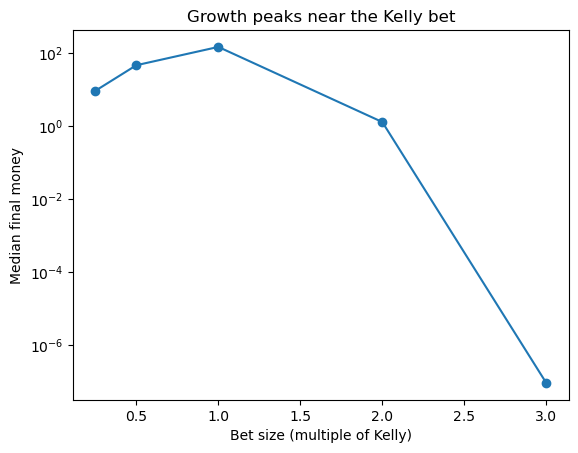

In [4]:
plt.plot(results["kelly_multiple"], results["median_final_money"], marker="o")
plt.xlabel("Bet size (multiple of Kelly)")
plt.ylabel("Median final money")
plt.yscale("log")
plt.title("Growth peaks near the Kelly bet")
plt.show()

## Takeaway
Betting 10% (1x Kelly) grows my money the fastest. Betting double (2x) barely grows it. Betting triple (3x) almost wipes me out, even though the coin is in my favor.

**Limitations:** I assume I know the exact win chance, and that each flip is independent. Results change slightly each time the random seed changes.